In [47]:
import sys
import os
import json
import numpy as np
import scipy as sp

sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_worm import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../worm-control/src'))
from utils_worm_control import read_utils as read_utils_control

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from utils import analysis_utils

from utils import ai_slob

In [48]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(analysis_utils)

<module 'utils.analysis_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/analysis_utils.py'>

In [3]:
organism = 'worm'

ll = 'll00'
data_variant = 'gcamp'
model_variant = 'ns'
manual = False
full = False

save = False

In [34]:
file_ids = list(range(0, 33+1))
# file_ids = [19]

In [35]:
filenames = analysis_utils.read_filenames(organism, file_ids)

model_path = read_utils.get_model_path()

metadata = (filenames, model_path, model_variant, data_variant, manual, full)

In [12]:
((boms_spn, _, _, _, _, _, _),
 (hgms_spn, _, _, _, _, _, _)) = analysis_utils.read_predictionss(*metadata)

In [13]:
neuron_scores = analysis_utils.assemble_scores(boms_spn, hgms_spn)

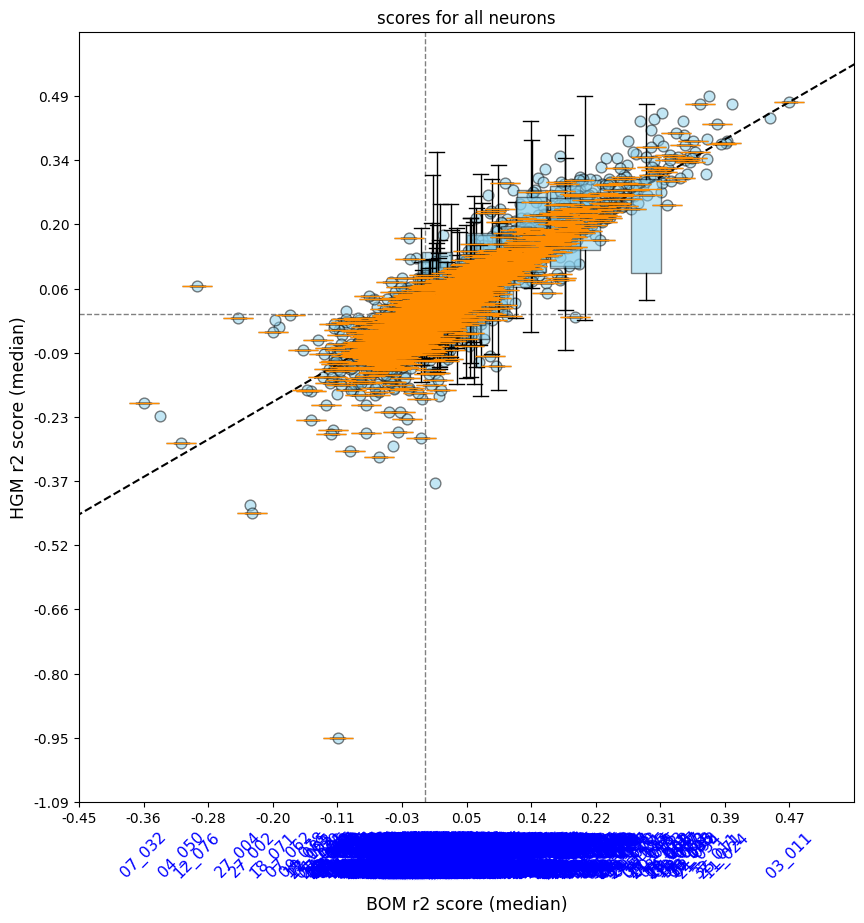

In [14]:
plot_utils.plot_performance_plot(
	neuron_scores, None,
	title='scores for all neurons', limits=None, force_medians=True, horizontal_bps=False,
	save_path=f'../../out/plots/scores/{model_variant}_scores_all' if save else None
)

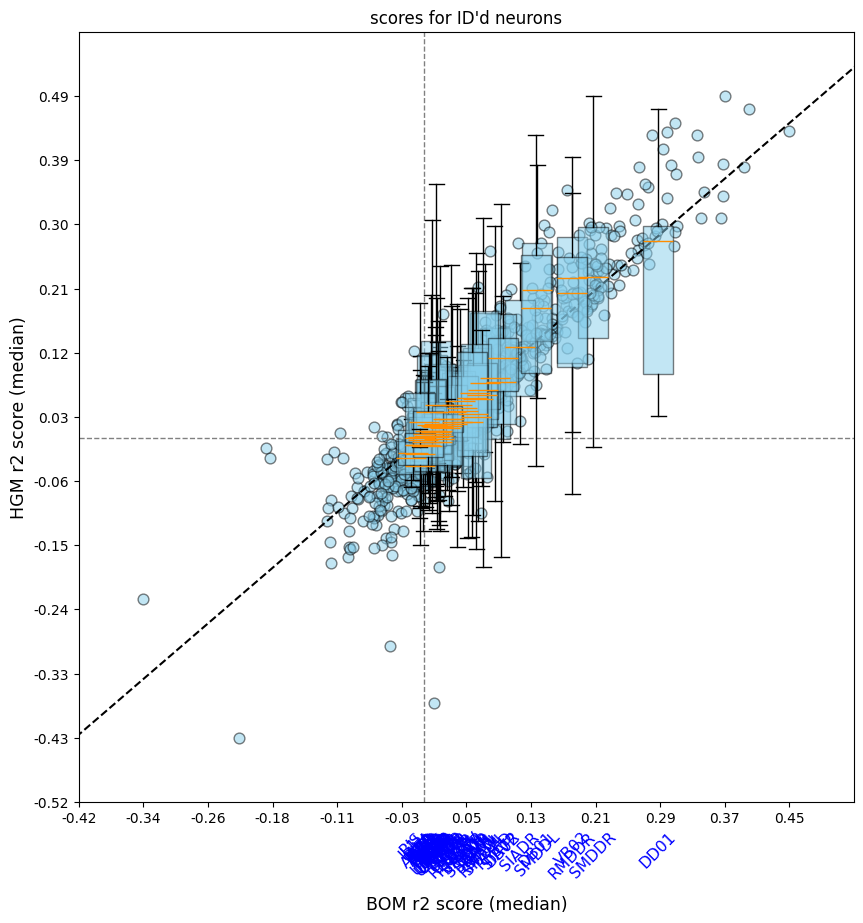

In [15]:
plot_utils.plot_performance_plot(
	{key: neuron_scores[key] for key in neuron_scores.keys() if not key[0].isdigit()}, None,
	title='scores for ID\'d neurons', limits=None, horizontal_bps=False,
	save_path=f'../../out/plots/scores/{model_variant}_scores_id' if save else None
)

# GFP control

In [16]:
file_ids_gfp = range(0, 7+1)
# file_ids_gfp = [2, 3]

filenames_gfp = analysis_utils.read_filenames(organism, file_ids_gfp, data_variant='gfp')
metadata_gfp = (filenames_gfp, model_path, model_variant, 'gfp', manual, full)

((boms_spn_gfp, _, _, _, _, _, _),
 (hgms_spn_gfp, _, _, _, _, _, _)) = analysis_utils.read_predictionss(filenames_gfp, model_path, model_variant, 'gfp', manual, full)
neuron_scores_gfp = analysis_utils.assemble_scores(boms_spn_gfp, hgms_spn_gfp)

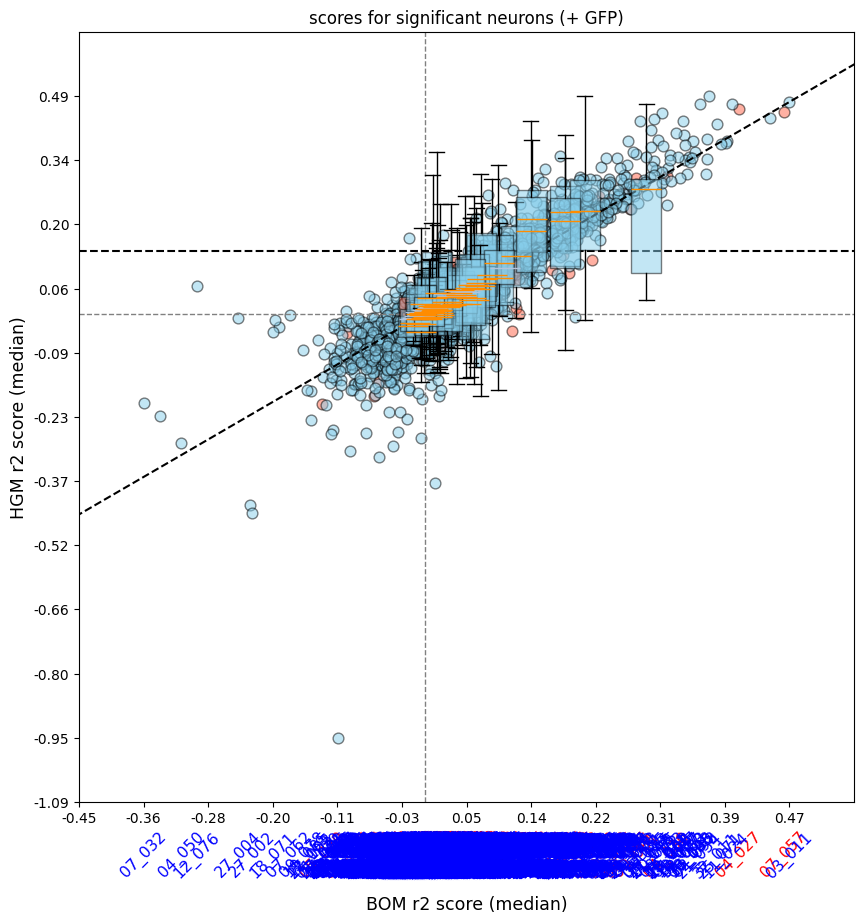

In [17]:
plot_utils.plot_performance_plot(
	neuron_scores, neuron_scores_gfp,
	title='scores for significant neurons (+ GFP)', limits=None, force_medians=False, control_cutoff=False, horizontal_bps=False,
	save_path=f'../../out/plots/scores/{model_variant}_scores_all_gfp' if save else None
)

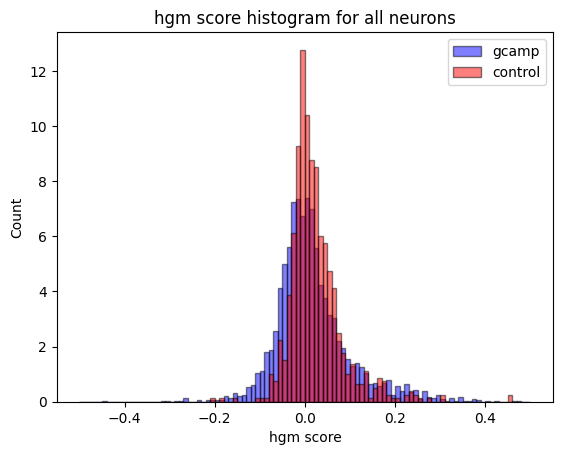

In [20]:
plot_utils.plot_performance_histogram(neuron_scores,
									  neuron_scores_gfp,
									  bins=100, range=(-0.5, 0.5),
									  title='hgm score histogram for all neurons')

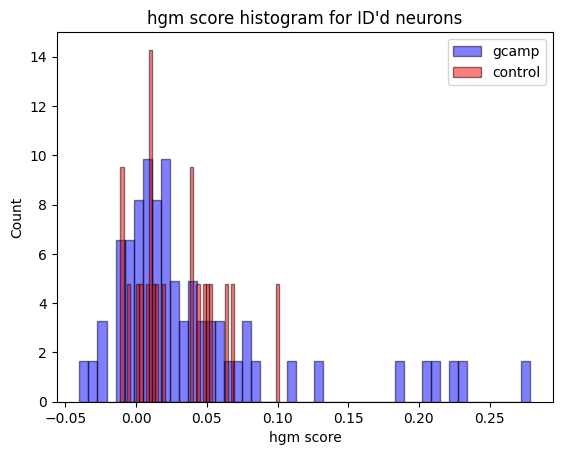

In [21]:
plot_utils.plot_performance_histogram({key: neuron_scores[key] for key in neuron_scores if not key[0].isdigit()},
									  {key: neuron_scores_gfp[key] for key in neuron_scores_gfp if not key[0].isdigit()},
									  bins=50,
									  title='hgm score histogram for ID\'d neurons')

In [22]:
threshold_hgm_gfp = np.quantile(np.concatenate([pair[1] for pair in neuron_scores_gfp.values()]), 0.95)
threshold_bom_gfp = np.quantile(np.concatenate([pair[0] for pair in neuron_scores_gfp.values()]), 0.95)
threshold_bom_gfp = np.array(0)

neuron_scores_hgm_sig = list(reversed(sorted({key: value for key, value in neuron_scores.items() if np.median(value[1].reshape(-1, 1)) > threshold_hgm_gfp and np.median(value[0].reshape(-1, 1)) > threshold_bom_gfp}.items(), key=lambda x: np.median(x[1][1]))))
neuron_scores_hgm_sig_labels = list([val[0] for val in neuron_scores_hgm_sig])

print('\n'.join([f'NEURON: {key},\t\tHGMSCR: {np.median(val[1]):.4f}' for key, val in neuron_scores_hgm_sig if not key[0].isdigit()]))

NEURON: DD01,		HGMSCR: 0.2788
NEURON: SMDDR,		HGMSCR: 0.2284
NEURON: VB02,		HGMSCR: 0.2267
NEURON: SMDDL,		HGMSCR: 0.2103
NEURON: RMDDR,		HGMSCR: 0.2062
NEURON: DB01,		HGMSCR: 0.1844


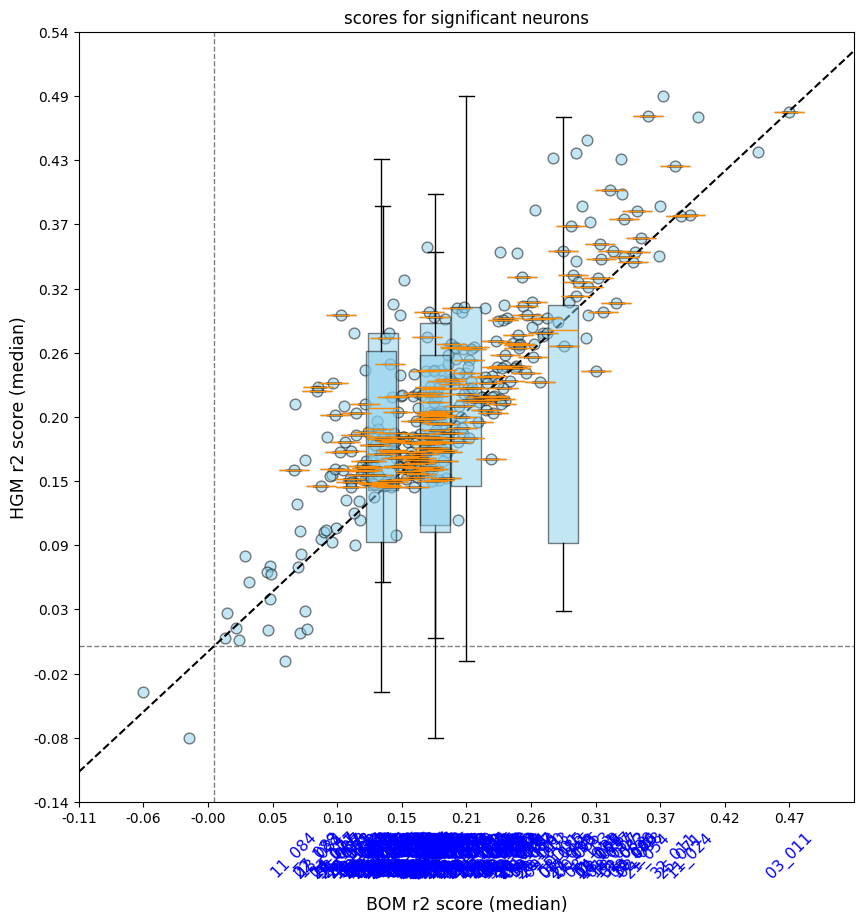

In [23]:
plot_utils.plot_performance_plot(
	{key: neuron_scores[key] for key in neuron_scores_hgm_sig_labels}, None,
	title='scores for significant neurons', limits=None, force_medians=True, horizontal_bps=False,
	save_path=f'../../out/plots/scores/{model_variant}_scores_significant' if save else None
)

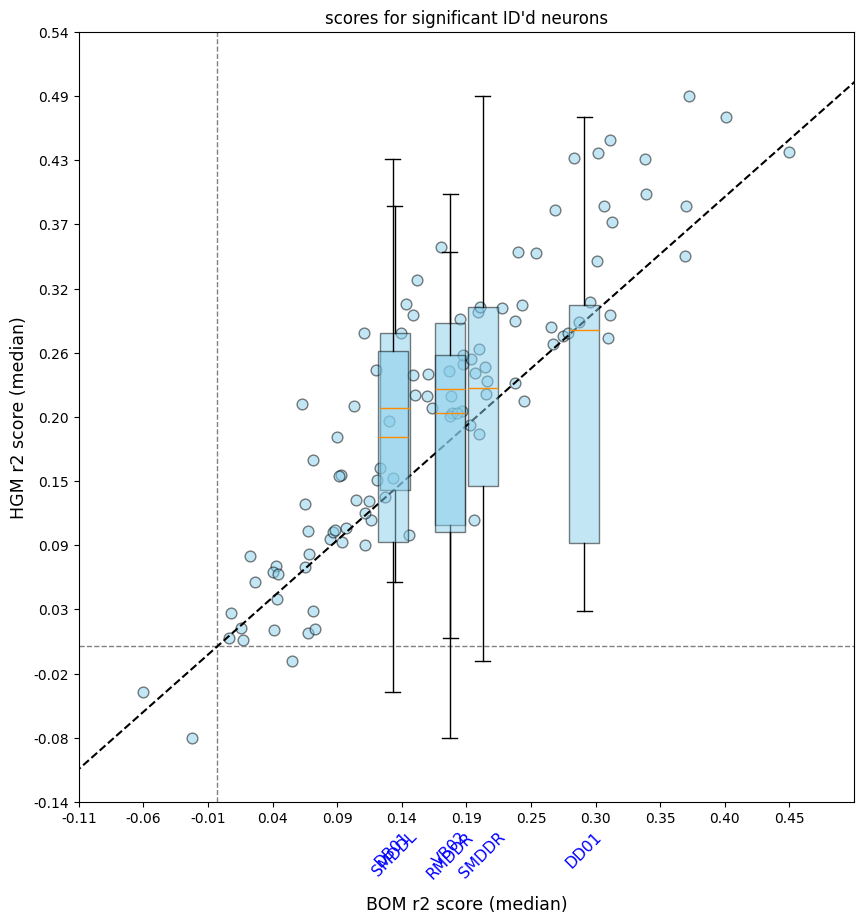

In [24]:
plot_utils.plot_performance_plot(
	{key: neuron_scores[key] for key in neuron_scores_hgm_sig_labels if not key[0].isdigit()}, None,
	title='scores for significant ID\'d neurons', limits=None, horizontal_bps=False,
	save_path=f'../../out/plots/scores/{model_variant}_scores_id_significant' if save else None
)

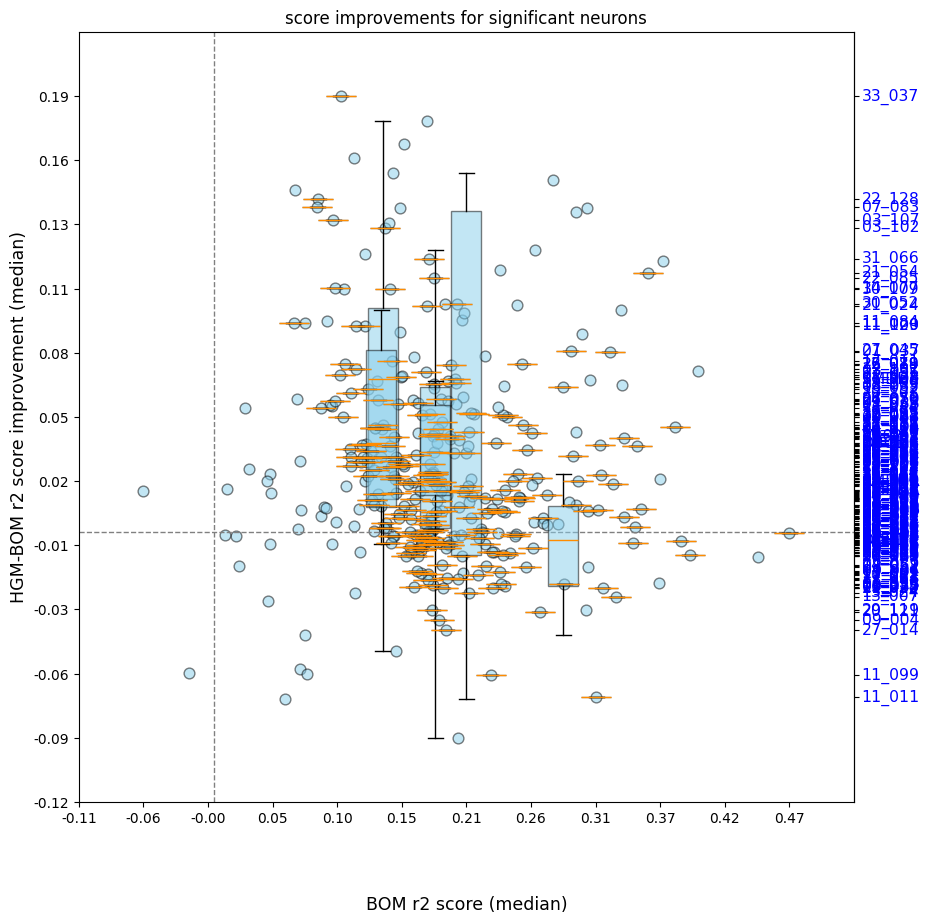

In [25]:
plot_utils.plot_improvement_plot(
	{key: neuron_scores[key] for key in neuron_scores_hgm_sig_labels},
	title='score improvements for significant neurons', limits=None, force_medians=True, horizontal_bps=False,
	save_path=f'../../out/plots/scores/{model_variant}_impros_significant' if save else None
)

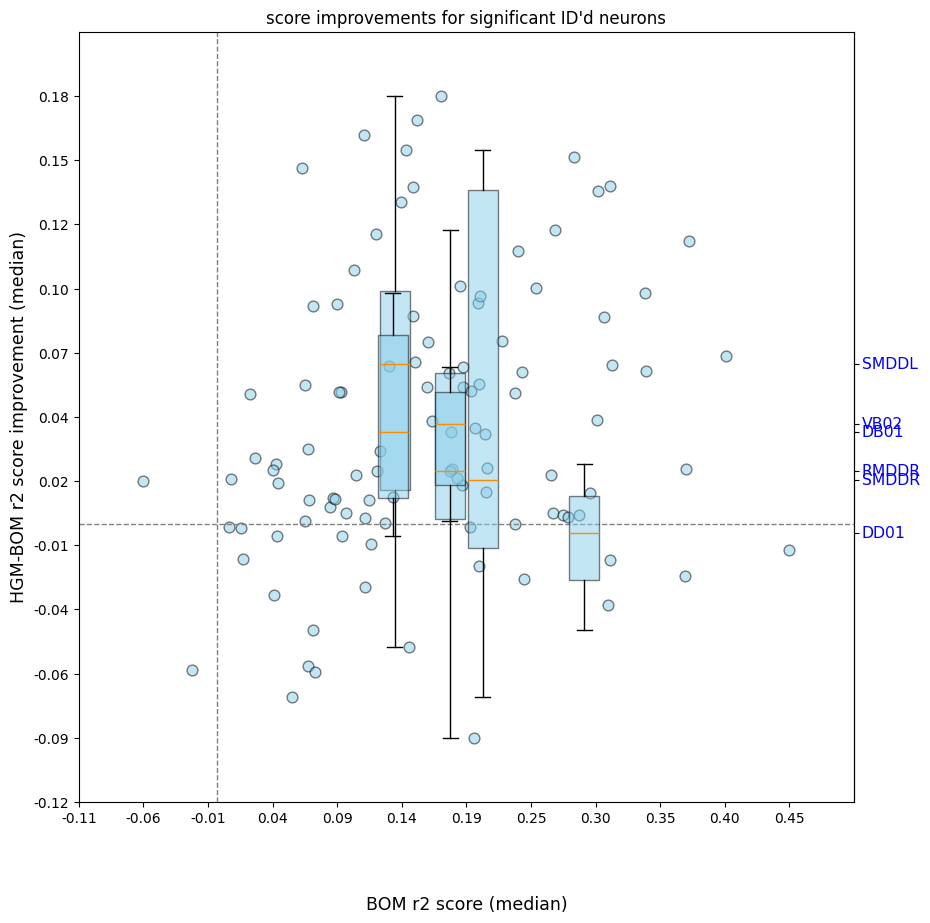

In [26]:
plot_utils.plot_improvement_plot(
	{key: neuron_scores[key] for key in neuron_scores_hgm_sig_labels if not key[0].isdigit()}, None,
	title='score improvements for significant ID\'d neurons', limits=None, horizontal_bps=False,
	save_path=f'../../out/plots/scores/{model_variant}_impros_id_significant' if save else None
)

In [27]:
neuron_impros_hgm_sig = list(reversed(sorted(neuron_scores_hgm_sig, key=lambda x: np.median(x[1][1] - x[1][0]))))
neuron_impros_hgm_rel_labels = list([val[0] for val in neuron_impros_hgm_sig])

print('\n'.join([f'NEURON: {key},\t\tIMPR: {np.median(val[1] - val[0]):.4f}' for key, val in neuron_impros_hgm_sig if not key[0].isdigit()]))

NEURON: SMDDL,		IMPR: 0.0662
NEURON: VB02,		IMPR: 0.0415
NEURON: DB01,		IMPR: 0.0382
NEURON: RMDDR,		IMPR: 0.0220
NEURON: SMDDR,		IMPR: 0.0181
NEURON: DD01,		IMPR: -0.0036


In [28]:
print('Neuron names for copying:')
print(', '.join([f'\'{label}\'' for label in neuron_impros_hgm_rel_labels if not label[0].isdigit()]))

Neuron names for copying:
'SMDDL', 'VB02', 'DB01', 'RMDDR', 'SMDDR', 'DD01'


# shuffle control

In [36]:
shuffle_scores = list()
for shuffle_id in range(100):
	((boms_spn, _, _, _, _, _, _),
	 (hgms_spn, _, _, _, _, _, _)) = analysis_utils.read_scoress(filenames, read_utils_control.get_model_path(shuffle_id), model_variant, data_variant, manual, full)
	shuffle_scores.append((boms_spn, hgms_spn))
neuron_scores_shuffle = [analysis_utils.assemble_scores(*shuffle_scores[i]) for i in range(100)]
shuffle_scores = None  # clear memory
neuron_scores_shuffle_merged = ai_slob.merge_neuron_scores_per_shuffle(neuron_scores_shuffle)

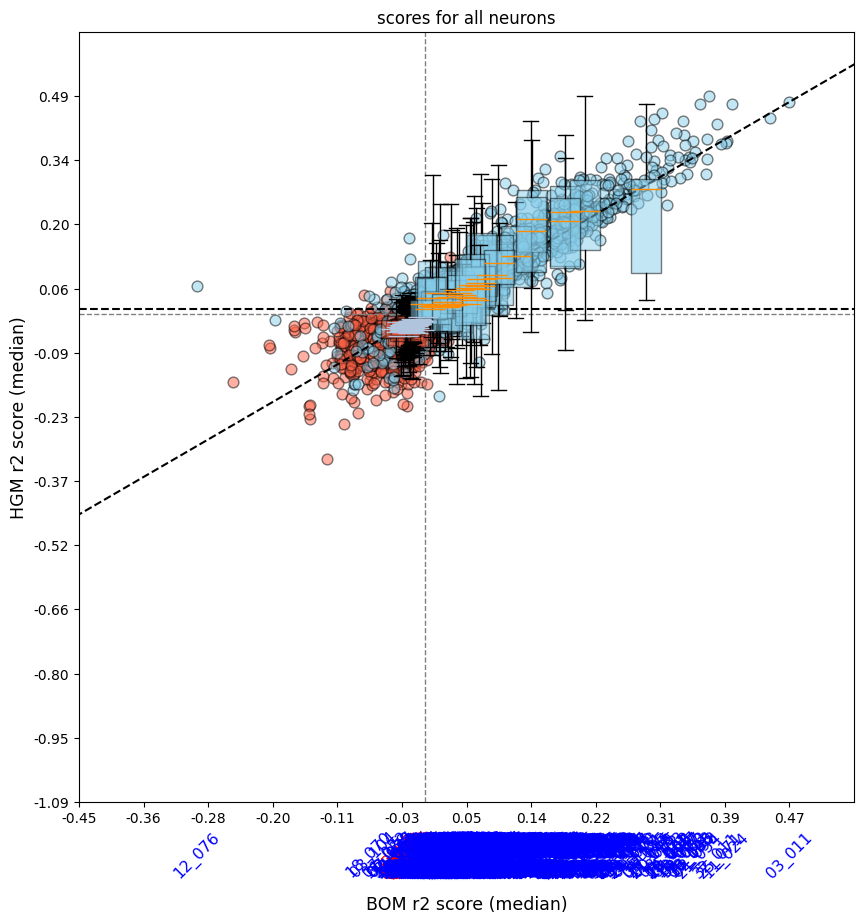

In [37]:
plot_utils.plot_performance_plot(
	neuron_scores, neuron_scores_shuffle_merged,
	title='scores for all neurons', limits=None, force_medians=False, horizontal_bps=False,
)

In [38]:
# compute HGM percentiles (default agg: mean of flattened array)
percentiles_hgm = ai_slob.compute_neuron_percentiles(
    neuron_scores,
    neuron_scores_shuffle,
    model='hgm'
)

# compute BOM percentiles
percentiles_bom = ai_slob.compute_neuron_percentiles(
    neuron_scores,
    neuron_scores_shuffle,
    model='bom'
)

# print top 10 ID'd neurons by HGM percentile
top10 = list(percentiles_hgm.items())[:]
for label, pct in top10:
	if not label[0].isdigit():
		print(f"{label}: {pct:.1f} percentile")

VB02: 100.0 percentile
SMDDR: 100.0 percentile
RMED: 100.0 percentile
SMDDL: nan percentile
RMDVL: 100.0 percentile
SAAVL: nan percentile
RMDVR: 99.0 percentile
URYDR: 92.0 percentile
URADR: 98.0 percentile
DD01: nan percentile
SMDVR: 100.0 percentile
RMEV: 100.0 percentile
URYVL: 98.0 percentile
DA01: nan percentile
SIADR: 100.0 percentile
URADL: 84.0 percentile
SIAVR: 100.0 percentile
SIADL: nan percentile
SMDVL: nan percentile
SIAVL: 100.0 percentile
URYVR: 97.0 percentile
AVAL: 100.0 percentile
URXL: 100.0 percentile
RMDDL: 100.0 percentile
AVEL: nan percentile
AQR: 98.0 percentile
RIVL: 99.0 percentile
ALA: nan percentile
AVAR: 100.0 percentile
RMER: 99.0 percentile
RMEL: 91.0 percentile
VB01: nan percentile
IL2R: 84.0 percentile
SAAVR: 100.0 percentile
RIML: nan percentile
RIBR: nan percentile
RID: 77.0 percentile
IL1R: nan percentile
BAGR: 97.0 percentile
RIVR: 100.0 percentile
RMDDR: 100.0 percentile
DB02: nan percentile
URYDL: 94.0 percentile
RIMR: nan percentile
URXR: 99.0 pe

In [52]:
importlib.reload(ai_slob)

<module 'utils.ai_slob' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/ai_slob.py'>

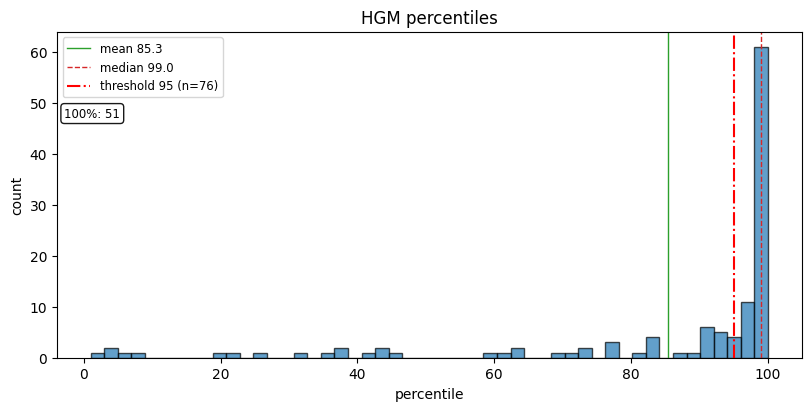

(array([ 1.,  2.,  1.,  1.,  0.,  0.,  0.,  0.,  0.,  1.,  1.,  0.,  1.,
         0.,  0.,  1.,  0.,  1.,  2.,  0.,  1.,  2.,  1.,  0.,  0.,  0.,
         0.,  0.,  0.,  1.,  1.,  2.,  0.,  0.,  1.,  1.,  2.,  0.,  3.,
         0.,  1.,  4.,  0.,  1.,  1.,  6.,  5.,  4., 11., 61.]),
 array([  1.  ,   2.98,   4.96,   6.94,   8.92,  10.9 ,  12.88,  14.86,
         16.84,  18.82,  20.8 ,  22.78,  24.76,  26.74,  28.72,  30.7 ,
         32.68,  34.66,  36.64,  38.62,  40.6 ,  42.58,  44.56,  46.54,
         48.52,  50.5 ,  52.48,  54.46,  56.44,  58.42,  60.4 ,  62.38,
         64.36,  66.34,  68.32,  70.3 ,  72.28,  74.26,  76.24,  78.22,
         80.2 ,  82.18,  84.16,  86.14,  88.12,  90.1 ,  92.08,  94.06,
         96.04,  98.02, 100.  ]))

In [44]:
ai_slob.plot_percentile_hist(percentiles_hgm, bins=50, title='HGM percentiles', threshold=95)

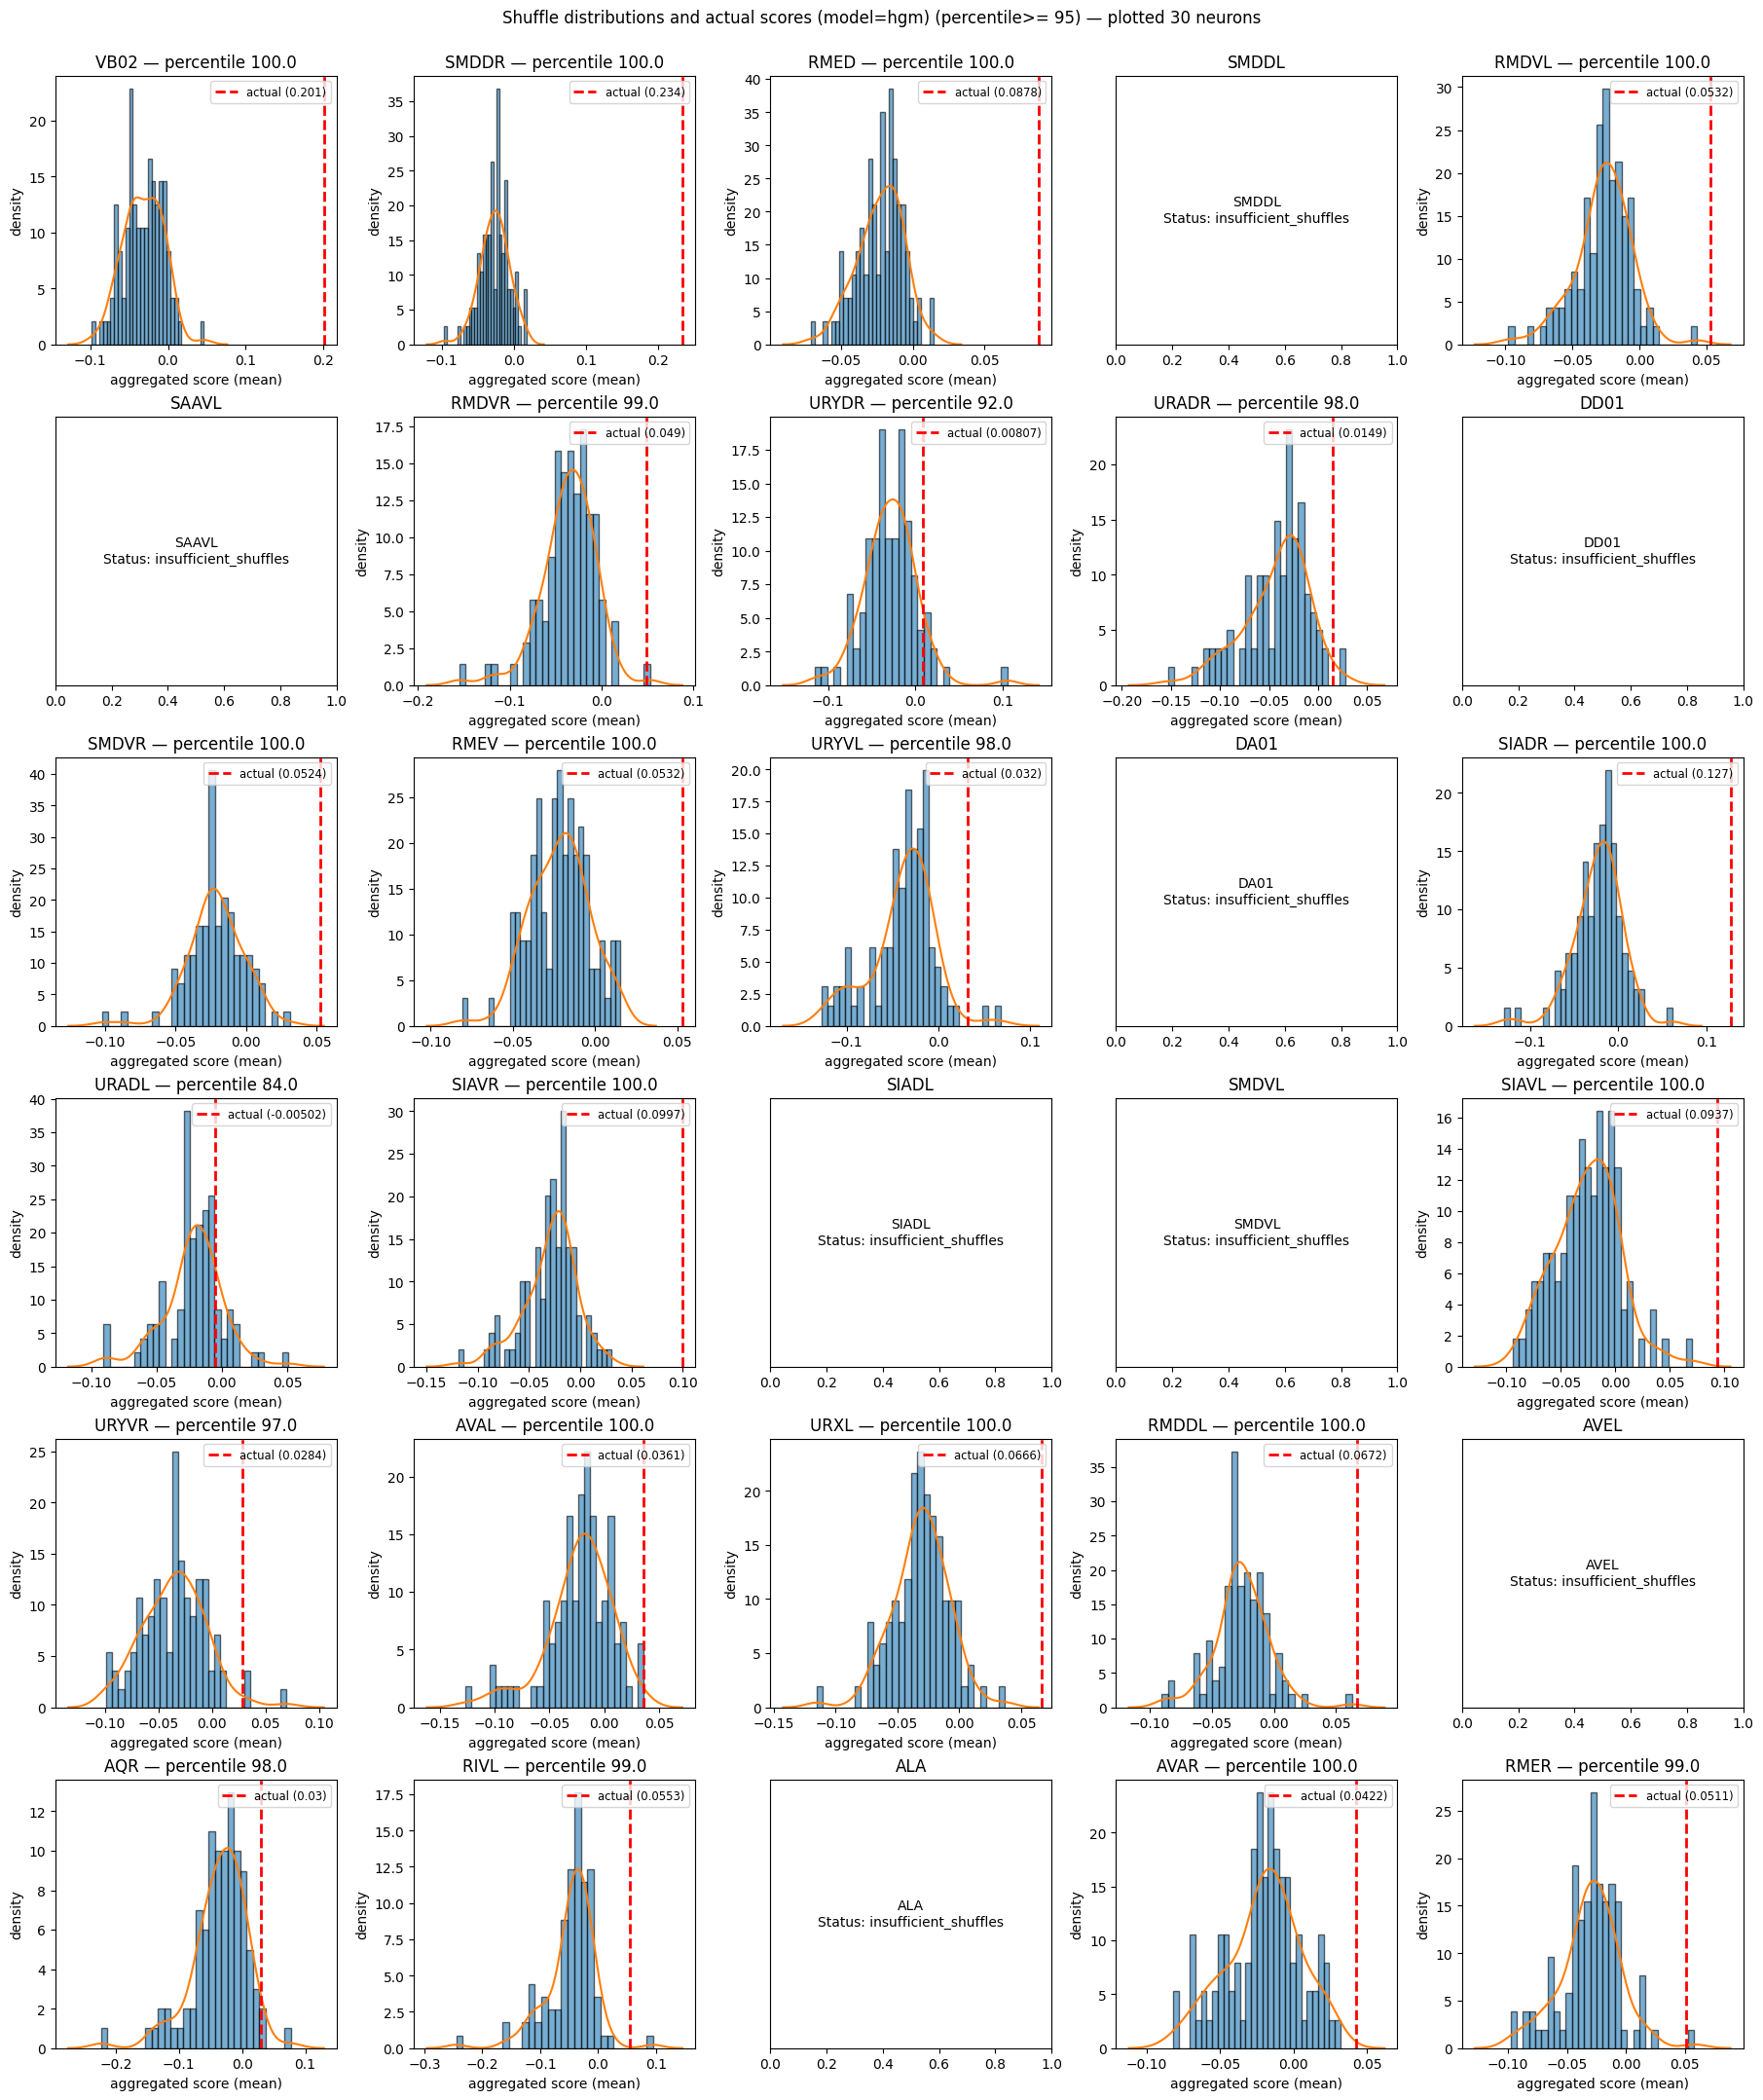

Plotted neurons: None


In [41]:
# Example usage: plots the top-10 neurons by actual HGM score
chosen = ai_slob.plot_first_n_neurons(neuron_scores, neuron_scores_shuffle, model='hgm', n=30, neuron_labels=[label for label in neuron_scores.keys() if not label[0].isdigit()])
print("Plotted neurons:", chosen)

# If you want the literal insertion-order 'first 10 keys' instead, call:
# first10_insertion_order = list(neuron_scores.keys())[:10]
# chosen = plot_first_n_neurons(neuron_scores, neuron_scores_shuffle, model='hgm', neuron_labels=first10_insertion_order)